# Дисперсионный анализ (ANOVA / MANOVA) в Python

**Дисциплина:** Введение в анализ больших данных

**ANOVA** проверяет H0: средние отклика одинаковы по уровням фактора(ов).

- однофакторный: одна категориальная независимая;
- двухфакторный: два фактора + взаимодействие (`y ~ A * B`);
- **MANOVA**: несколько зависимых переменных сразу.

Инструменты: `statsmodels` (`ols`, `anova_lm`, `MANOVA`).

Демо: **tips** и **penguins**.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.multivariate.manova import MANOVA

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")


---
## 1. Двухфакторный ANOVA

ANalysis Of VAriance

Идея: проверить, различаются ли средние значения одной числовой переменной между группами, заданными категориальным фактором.

Нулевая гипотеза (H₀): средние во всех группах равны.
Альтернатива (H₁): хотя бы одно среднее отличается.

Логика названия
Хотя сравниваем средние, метод работает через дисперсию: раскладывает общую вариабельность отклика на две части:

межгрупповая (between-group) — насколько средние групп отличаются от общего среднего;

внутригрупповая (within-group, residual) — разброс внутри каждой группы.

Если межгрупповая дисперсия существенно больше внутригрупповой — значит группы реально разные. Отношение этих дисперсий и есть статистика F:

Чем больше F (и меньше p), тем увереннее отвергаем H₀.

Отклик `tip`, факторы `day` и `time` (датасет tips).

Формула `tip ~ day * time` = главные эффекты + взаимодействие.


In [2]:
tips = sns.load_dataset("tips")
print(tips.head())
print("\nЧастоты day × time:")
print(pd.crosstab(tips["day"], tips["time"]))


   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Частоты day × time:
time  Lunch  Dinner
day                
Thur     61       1
Fri       7      12
Sat       0      87
Sun       0      76


In [ ]:
agg = tips.groupby(["day", "time"])["tip"].agg(["mean", "std", "count"]).round(2)
print(agg)
# День и время - категориальные признаки. можем перебрать варианты и в каждом скажем медиану, ст. откл. и стандр. чаевые


             mean   std  count
day  time                     
Thur Lunch   2.77  1.25     61
     Dinner  3.00   NaN      1
Fri  Lunch   2.38  0.66      7
     Dinner  2.94  1.16     12
Sat  Lunch    NaN   NaN      0
     Dinner  2.99  1.63     87
Sun  Lunch    NaN   NaN      0
     Dinner  3.26  1.23     76


C:\Users\kirya\AppData\Local\Temp\ipykernel_24148\2925273643.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg = tips.groupby(["day", "time"])["tip"].agg(["mean", "std", "count"]).round(2)


In [4]:
tips = tips.copy()
tips["day"] = tips["day"].astype("category")
tips["time"] = tips["time"].astype("category")

model = smf.ols("tip ~ day * time", data=tips).fit()
print(anova_lm(model, typ=3))


               sum_sq     df           F        PR(>F)
Intercept  467.271621    1.0  244.816529  2.002206e-38
day          3.728339    3.0    0.651127  5.829573e-01
time         0.053091    1.0    0.027816  8.676845e-01
day:time     2.976109    3.0    0.519755  6.690786e-01
Residual   454.261182  238.0         NaN           NaN


C:\Users\kirya\AppData\Local\Temp\ipykernel_24148\1418311916.py:5: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = smf.ols("tip ~ day * time", data=tips).fit()


**Чтение таблицы ANOVA**

- для каждой строки: Sum Sq, F, PR(>F);
- p < 0.05 → эффект **значим**;



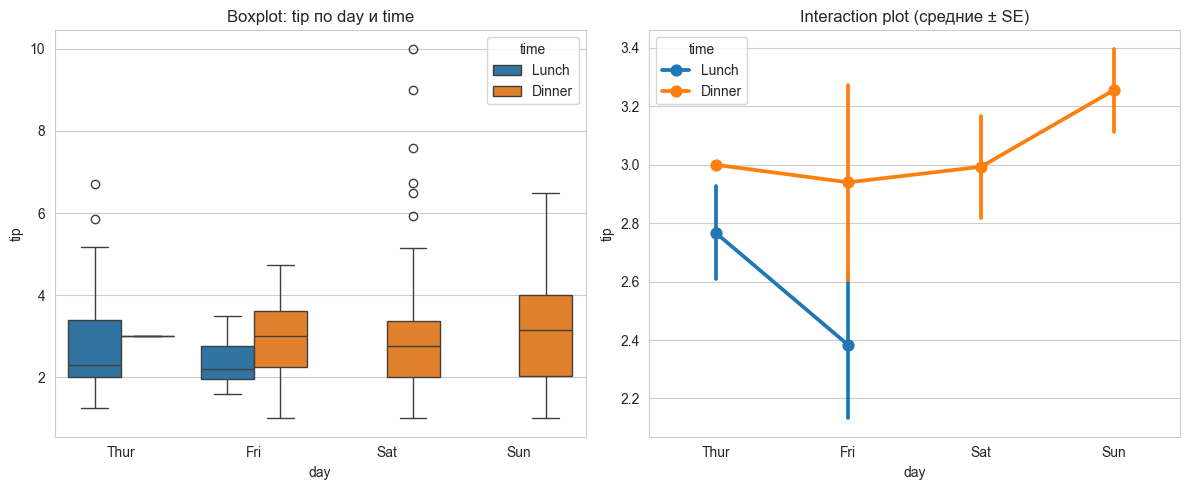

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=tips, x="day", y="tip", hue="time", ax=axes[0])
axes[0].set_title("Boxplot: tip по day и time")
sns.pointplot(data=tips, x="day", y="tip", hue="time", errorbar="se", ax=axes[1])
axes[1].set_title("Interaction plot (средние ± SE)")
plt.tight_layout()
plt.show()


---
## 2. Однофакторный ANOVA

Пример: зависит ли `total_bill` от `day`?


In [6]:
m1 = smf.ols("total_bill ~ day", data=tips).fit()
print(anova_lm(m1, typ=2))
print(tips.groupby("day")["total_bill"].mean().round(2))


                sum_sq     df         F    PR(>F)
day         643.941362    3.0  2.767479  0.042454
Residual  18614.522721  240.0       NaN       NaN
day
Thur    17.68
Fri     17.15
Sat     20.44
Sun     21.41
Name: total_bill, dtype: float64


C:\Users\kirya\AppData\Local\Temp\ipykernel_24148\1366650022.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tips.groupby("day")["total_bill"].mean().round(2))


---
## 3. MANOVA

Multivariate ANalysis Of VAriance

Идея: то же самое, что ANOVA, но откликов несколько сразу. Проверяем, различаются ли векторы средних между группами

Зачем нужен MANOVA, если можно сделать несколько ANOVA?
Учёт корреляций между откликами. Если Yslov_educ, Yslov_job, Yslov_science коррелируют, три отдельные ANOVA «не видят» этой структуры и могут дать ложноположительные результаты (проблема множественных сравнений).

Контроль ошибки I рода на уровне всей совокупности откликов.

Обнаружение эффектов, которые не видны по каждому отклику отдельно — различие есть в комбинации переменных, но не по каждой в отдельности.

Несколько зависимых переменных одновременно.  
H0: векторы средних одинаковы по группам.


In [7]:
peng = sns.load_dataset("penguins").dropna()
ys = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]
print("Средние по species:")
print(peng.groupby("species")[ys].mean().round(2))


Средние по species:
           bill_length_mm  bill_depth_mm  flipper_length_mm
species                                                    
Adelie              38.82          18.35             190.10
Chinstrap           48.83          18.42             195.82
Gentoo              47.57          15.00             217.24


In [8]:
formula = "bill_length_mm + bill_depth_mm + flipper_length_mm ~ C(species)"
maov = MANOVA.from_formula(formula, data=peng)
print(maov.mv_test())


                    Multivariate linear model
                                                                  
------------------------------------------------------------------
       Intercept         Value   Num DF  Den DF   F Value   Pr > F
------------------------------------------------------------------
          Wilks' lambda   0.0027 3.0000 328.0000 39821.1955 0.0000
         Pillai's trace   0.9973 3.0000 328.0000 39821.1955 0.0000
 Hotelling-Lawley trace 364.2183 3.0000 328.0000 39821.1955 0.0000
    Roy's greatest root 364.2183 3.0000 328.0000 39821.1955 0.0000
------------------------------------------------------------------
                                                                  
------------------------------------------------------------------
         C(species)        Value  Num DF  Den DF   F Value  Pr > F
------------------------------------------------------------------
            Wilks' lambda  0.0293 6.0000 656.0000  529.0985 0.0000
           Pilla

После значимого MANOVA смотрят **одномерные** ANOVA по каждой y.


In [9]:
print("=== Одномерные ANOVA ===")
for y in ys:
    m = smf.ols(f"{y} ~ C(species)", data=peng).fit()
    print(f"\n{y}:")
    print(anova_lm(m, typ=2))


=== Одномерные ANOVA ===

bill_length_mm:
                 sum_sq     df           F        PR(>F)
C(species)  7015.385745    2.0  397.299437  1.380984e-88
Residual    2913.516957  330.0         NaN           NaN

bill_depth_mm:
                sum_sq     df           F        PR(>F)
C(species)  870.785183    2.0  344.825082  1.446616e-81
Residual    416.673736  330.0         NaN           NaN

flipper_length_mm:
                  sum_sq     df           F         PR(>F)
C(species)  50525.883615    2.0  567.406992  1.587418e-107
Residual    14692.753022  330.0         NaN            NaN


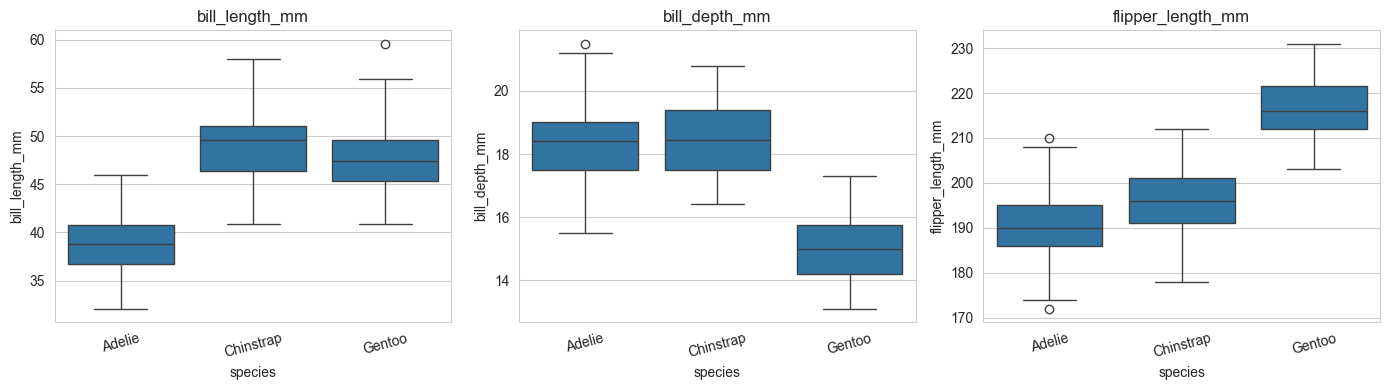

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, y in zip(axes, ys):
    sns.boxplot(data=peng, x="species", y=y, ax=ax)
    ax.set_title(y)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


### Как описать результаты

1. **ANOVA:** для A, B, A:B — F и p; p < 0.05 → эффект значим.  
2. Значимое взаимодействие — влияние одного фактора меняется по уровням другого.  
3. **MANOVA:** p < 0.05 → группы различаются в пространстве нескольких откликов.  
4. Затем — одномерные ANOVA и графики (boxplot / pointplot).

---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| ANOVA-модель | `smf.ols("y ~ A * B", data=df).fit()` |
| Таблица ANOVA | `anova_lm(model, typ=2)` |
| Средние по группам | `df.groupby(["A","B"])["y"].mean()` |
| MANOVA | `MANOVA.from_formula("y1 + y2 ~ F", data=df)` |
| Результат MANOVA | `maov.mv_test()` |
| Interaction plot | `sns.pointplot(..., hue=...)` |

---
## Что сделать после лекции

1. Откройте лабораторное задание и выполните ANOVA/MANOVA **самостоятельно** на своих CSV.  
2. Факторы удобно кодировать как `category`.

Удачи!


In [11]:
import os
from google.colab import files

print("Доступные файлы в рабочей директории:")
print(os.listdir())

uploaded = files.upload()
file_name = next(iter(uploaded))

if file_name.endswith('.csv'):
    data = pd.read_csv(file_name)
elif file_name.endswith('.xlsx'):
    data = pd.read_excel(file_name)
else:
    raise ValueError("Формат файла не поддерживается. Используйте CSV или Excel.")

print(f"\nФайл '{file_name}' успешно загружен!")
data.to_excel('data.xlsx')

ModuleNotFoundError: No module named 'google'